In [34]:
import numpy as np
from seekpath_web_module import get_magres
from ase.io import read, write

/Users/fedeparuzzo/miniconda2/lib/python2.7/site-packages/pymatgen/__init__.py:87: UserWarning: 
Pymatgen will drop Py2k support from v2019.1.1. Pls consult the documentation
at https://www.pymatgen.org for more details.
  at https://www.pymatgen.org for more details.""")
DEBUG:seekpath_server:Start


In [35]:
frame = read('/Users/fedeparuzzo/Downloads/EDEBUK.cif')

In [36]:
write('./file_examples/EDEBUK.xyz', frame)

In [37]:
with open('/Users/fedeparuzzo/Downloads/tmp.txt','r') as fin, open('/Users/fedeparuzzo/Downloads/tmp2.txt','w') as fout:
    for line in fin.readlines()[2:]:
        fout.write('%f\n' % float(line.split()[4]))

In [38]:
shielding = np.random.rand(len(frame))

In [39]:
shielding[10]

0.59658466275936484

In [40]:
with open('tmp.txt', 'w') as f:
    f.write('data \"property_shifts\"\n')
    for it in range(len(shielding)):
        f.write('{}\n'.format(shielding[it]))
    f.write('end \"property_shifts\"\n')

In [35]:
with open('tmp.txt', 'w') as f:
    f.write('data \"property_shifts\"\n')
    f.write('{}\n'.format(np.array2string(shielding[0:2], separator='\n')))
    f.write('end \"property_shifts\"\n')

In [4]:
from structure_importers.magres_io import write_magres
numbers = frame.get_atomic_numbers()
positions = frame.get_positions()
cell = frame.get_cell()
pbc = frame.get_pbc()
new_frame = Atoms(numbers=numbers, positions=positions, cell=cell, pbc=pbc)
new_frame.set_array('iso_cs'.encode('ascii', 'ignore'), shielding)
new_frame.info = {'magres_units': {'iso_cs': 'ppm'},
                  'magresblock_calculation': {'calc_code': [['ML_NMR']],
                                              'calc_code_version': [['svnunknown']],
                                              'calc_name': [['gpr']]}
                  }

f_obj = DummyFileObject()

write_magres(f_obj, new_frame)
f_obj.read()

#$magres-abinitio-v1.0
# Generated by the Atomic Simulation Environment library
[calculation]
calc_code ML_NMR
calc_code_version svnunknown
calc_name gpr
[/calculation]
[atoms]
  units lattice Angstrom
  units atom Angstrom
  lattice 8.206047178 0.0 0.0 0.0 4.74602482773 0.0 0.0 0.0 10.6000629696
  atom O O 1 3.91160933253 0.617357341295 8.55700340371
  atom O O 2 4.29443784547 4.12866748643 3.25698012495
  atom O O 3 8.01463292153 4.12866748643 8.55700340371
  atom O O 4 0.191414256474 0.617357341295 3.25698012495
  atom O O 5 4.74240596092 3.69338591992 0.328791692281
  atom O O 6 3.46364121708 1.05263890781 5.62882317709
  atom O O 7 0.639382371921 1.05263890781 0.328791692281
  atom O O 8 7.56666480608 3.69338591992 5.62882317709
  atom H H 1 4.18844033408 4.58645824035 0.539531189859
  atom H H 2 4.01760684392 0.159566587376 5.83956267467
  atom H H 3 0.0854167450758 0.159566587376 0.539531189859
  atom H H 4 8.12063043292 4.58645824035 5.83956267467
  atom O O 9 6.26974007983 1.4

/home/musil/miniconda/envs/glosim/lib/python2.7/site-packages/pymatgen/__init__.py:87: UserWarning: 
Pymatgen will drop Py2k support from v2019.1.1. Pls consult the documentation
at https://www.pymatgen.org for more details.
  at https://www.pymatgen.org for more details.""")


In [41]:
import pickle as pck
from libmatch.soap import get_Soaps
def ase2qp(aseatoms):
    from quippy import Atoms as qpAtoms
    positions = aseatoms.get_positions()
    cell = aseatoms.get_cell()
    numbers = aseatoms.get_atomic_numbers()
    pbc = aseatoms.get_pbc()
    return qpAtoms(numbers=numbers,cell=cell,positions=positions,pbc=pbc)

spkitMax = {8: 88, 1: 132, 6: 148, 7: 112}

z2symb = {
    1: 'H', 2: 'He', 3: 'Li', 4: 'Be', 5: 'B', 6: 'C', 7: 'N',
          8: 'O', 9: 'F', 10: 'Ne', 11: 'Na', 12: 'Mg', 13: 'Al',
          14: 'Si', 15: 'P',
          16: 'S', 17: 'Cl', 18: 'Ar', 19: 'K', 20: 'Ca', 21: 'Sc',
          22: 'Ti', 23: 'V', 24: 'Cr', 25: 'Mn', 26: 'Fe', 27: 'Co',
          28: 'Ni', 29: 'Cu', 30: 'Zn', 31: 'Ga', 32: 'Ge', 33: 'As',
          34: 'Se', 35: 'Br', 36: 'Kr', 37: 'Rb', 38: 'Sr', 39: 'Y',
          40: 'Zr', 41: 'Nb', 42: 'Mo', 43: 'Tc', 44: 'Ru', 45: 'Rh',
          46: 'Pd', 47: 'Ag', 48: 'Cd', 49: 'In', 50: 'Sn', 51: 'Sb',
          52: 'Te', 53: 'I', 54: 'Xe', 55: 'Cs', 56: 'Ba', 57: 'La',
          58: 'Ce', 59: 'Pr', 60: 'Nd', 62: 'Sm', 63: 'Eu', 64: 'Gd',
          65: 'Tb', 66: 'Dy', 67: 'Ho', 68: 'Er', 69: 'Tm', 70: 'Yb',
          71: 'Lu', 72: 'Hf', 73: 'Ta', 74: 'W', 75: 'Re', 76: 'Os',
          77: 'Ir', 78: 'Pt', 79: 'Au', 80: 'Hg', 81: 'Tl', 82: 'Pb',
          83: 'Bi'
}

def get_Nsoap(spkitMax, nmax, lmax):
    Nsoap = 0
    for sp1 in spkitMax:
        for sp2 in spkitMax:
            if sp1 == sp2:
                Nsoap += nmax * (nmax + 1) * (lmax + 1) / 2
            elif sp1 > sp2:
                Nsoap += nmax ** 2 * (lmax + 1)
    return Nsoap + 1

def load_model_data(sp):
    '''
    Load the model data at the start of the app
    :return:
    '''
    from seekpath_app import dataPath

    with open(dataPath + 'model_sp_{}.pck'.format(z2symb[sp]), 'rb') as f:
        model = pck.load(f)
    return model
def get_fingerprints(frames, soap_params, nprocess, sp=None):
    fings = get_Soaps(frames, nprocess=nprocess, **soap_params)
    if sp is not None:
        N = 0
        for cc in frames:
            numbers = cc.get_atomic_numbers()
            N += len(numbers[numbers == sp])
    else:
        N = 0
        for cc in frames:
            numbers = cc.get_atomic_numbers()
            N += len(numbers)

    Nsoap = get_Nsoap(spkitMax, soap_params['nmax'], soap_params['lmax'])
    soaps = np.zeros((N, Nsoap))
    if sp is not None:
        ii = 0
        for iframe, fing in enumerate(fings):
            numbers = fing.get_atomic_numbers()
            n = len(numbers[numbers == sp])
            centers = [fing[z2symb[sp] + str(it)] for it in range(n)]
            for icenter, center in enumerate(centers):
                soaps[ii] = center
                ii += 1
    else:
        ii = 0
        for iframe, fing in enumerate(fings):
            numbers = fing.get_atomic_numbers()
            n = len(numbers[numbers == sp])
            centers = fing.values()
            for icenter, center in enumerate(centers):
                soaps[ii] = center
                ii += 1
    return soaps

def predict(kernel, alpha, csi):
    return np.dot(alpha, np.power(kernel, csi, out=kernel)).reshape((-1))
def shielding2shifts(shielding,slope,intercept):
    shifts=intercept-slope*shielding
    return shifts
def load_model_data_msk(sp,cutoff):
    '''
    Load the model data at the start of the app
    :return:
    '''
    from seekpath_app import dataPath
    print dataPath + 'model_sp_{}_c_{}.pck'.format(z2symb[sp],cutoff)
    with open(dataPath + 'model_sp_{}_c_{}.pck'.format(z2symb[sp],cutoff), 'rb') as f:
        model = pck.load(f)
    return model

slopes={1:1,6:1,7:1,8:1}
intercepts={1:30.8,6:169.5,7:0,8:0}

In [376]:
idx=np.where(t == shielding[numbers == sp])
print idx

(array([], dtype=int64),)


/Users/fedeparuzzo/miniconda2/lib/python2.7/site-packages/ipykernel_launcher.py:1: DeprecationWarning: elementwise == comparison failed; this will raise an error in the future.
  """Entry point for launching an IPython kernel.


In [1]:
shielding=[ 3.04,  3.04,  3.56,  3.56,  6.22,  6.22,  3.48,  3.48,  2.28,
        2.28,  2.43,  2.43,  2.1 ,  2.1 ,  2.8 ,  2.8 ,  1.69,  1.69,
        1.84,  1.84,  0.86,  0.86,  2.12,  2.12,  1.15,  1.15,  7.96,
        7.96,  6.94,  6.94,  7.45,  7.45,  8.16,  8.16,  7.64,  7.64,
        4.35,  4.35,  4.06,  4.06,  4.23,  4.23]

In [12]:
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [27]:
bins=np.linspace(0,10,1000)

In [22]:
bins=int(((max(shielding))-(min(shielding)))/0.01)

In [6]:
sns.distplot?

In [9]:
plt.hist?

In [13]:
np.histogram?

In [21]:
shielding

[3.04,
 3.04,
 3.56,
 3.56,
 6.22,
 6.22,
 3.48,
 3.48,
 2.28,
 2.28,
 2.43,
 2.43,
 2.1,
 2.1,
 2.8,
 2.8,
 1.69,
 1.69,
 1.84,
 1.84,
 0.86,
 0.86,
 2.12,
 2.12,
 1.15,
 1.15,
 7.96,
 7.96,
 6.94,
 6.94,
 7.45,
 7.45,
 8.16,
 8.16,
 7.64,
 7.64,
 4.35,
 4.35,
 4.06,
 4.06,
 4.23,
 4.23]

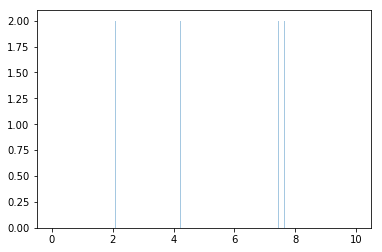

In [29]:
sns.distplot(shielding,bins=bins,kde=False)

In [435]:
shielding[numbers == sp]

array([ 3.04,  3.04,  3.56,  3.56,  6.22,  6.22,  3.48,  3.48,  2.28,
        2.28,  2.43,  2.43,  2.1 ,  2.1 ,  2.8 ,  2.8 ,  1.69,  1.69,
        1.84,  1.84,  0.86,  0.86,  2.12,  2.12,  1.15,  1.15,  7.96,
        7.96,  6.94,  6.94,  7.45,  7.45,  8.16,  8.16,  7.64,  7.64,
        4.35,  4.35,  4.06,  4.06,  4.23,  4.23])

In [470]:
if llim[sp]>min(shielding[numbers == sp]):
    llim[sp]=min(shielding[numbers == sp])-increment[sp]
if rlim[sp]<max(shielding[numbers == sp]):
    rlim[sp]=max(shielding[numbers == sp])+increment[sp]
t = np.arange(llim[sp], rlim[sp], 0.01)

array([], dtype=float64)

In [525]:
ax.tick_params(direction='out', length=6, width=2, colors='r',
               grid_color='r', grid_alpha=0.5)

AttributeError: 'module' object has no attribute 'tick_params'

In [30]:
def create_plot(sp,shieldings):
    colors={1:'#1d4484',6:'#E42828',7:'#A3CB58',8:'#F47531'}
    increment={1:2,6:5,7:10,8:10}
    simbols={1:'H',6:'C',7:'N',8:'O'}
    labels={1:'$^1$H',6:'$^{13}$C',7:'$^{15}$N',8:'$^{17}$O'}


    '''
    llim={1:-2,6:-5,7:-10,8:-50}
    rlim={1:12,6:200,7:400,8:400}
    if llim[sp]>min(shielding[numbers == sp]):
        llim[sp]=min(shielding[numbers == sp])-increment[sp]
    if rlim[sp]<max(shielding[numbers == sp]):
        rlim[sp]=max(shielding[numbers == sp])+increment[sp]
    t = np.arange(llim[sp], rlim[sp], 0.01)
    '''

    f = np.arange((min(shielding[numbers == sp])-increment[sp]), (max(shielding[numbers == sp])+increment[sp]), 0.01)
    i = np.zeros(len(f))
    idx=[np.isclose(f, it) for it in shielding[numbers == sp]]
    i[np.where(sum(idx)<>0)]=1
    plt.figure(figsize=(12,5),frameon=False)
    plt.tick_params(axis='y',which='both',left='off', labelleft='off')
    plt.plot(f,i,color=colors[sp])
    ax = plt.gca()
    ax.tick_params(direction='in', length=3, width=2, labelsize=16, pad=10)
    ax.yaxis.set_ticks_position('none') 
    ax.spines['left'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.set_xlim(min(f), max(f));
    ax.set_xlabel("{} Chemical Shifts / ppm".format(labels[sp]),fontsize=22)
    plt.savefig('static/jsmol/data/uploaded/{}SPECTRUM_UPLOADED.png'.format(simbols[sp]),bbox_inches='tight')
    return 1


In [65]:
def create_plot(sp,shieldings):
    colors={1:'#1d4484',6:'#E42828',7:'#A3CB58',8:'#F47531'}
    increment={1:2,6:5,7:10,8:10}
    simbols={1:'H',6:'C',7:'N',8:'O'}
    labels={1:'$^1$H',6:'$^{13}$C',7:'$^{15}$N',8:'$^{17}$O'}


    '''
    llim={1:-2,6:-5,7:-10,8:-50}
    rlim={1:12,6:200,7:400,8:400}
    if llim[sp]>min(shielding[numbers == sp]):
        llim[sp]=min(shielding[numbers == sp])-increment[sp]
    if rlim[sp]<max(shielding[numbers == sp]):
        rlim[sp]=max(shielding[numbers == sp])+increment[sp]
    t = np.arange(llim[sp], rlim[sp], 0.01)
    '''

    f = np.arange((min(shieldings)-increment[sp]), (max(shieldings)+increment[sp]), 0.01)
    i = np.zeros(len(f))
    idx=[np.isclose(f, it) for it in shieldings]
    i[np.where(sum(idx)<>0)]=1
    plt.figure(figsize=(12,5),frameon=False)
    plt.tick_params(axis='y',which='both',left='off', labelleft='off')
    plt.plot(f,i,color=colors[sp])
    ax = plt.gca()
    ax.tick_params(direction='in', length=3, width=2, labelsize=16, pad=10)
    ax.yaxis.set_ticks_position('none') 
    ax.spines['left'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['top'].set_visible(False)
    ax.set_xlim(min(f), max(f));
    ax.set_xlabel("{} Chemical Shifts / ppm".format(labels[sp]),fontsize=22)
    plt.savefig('static/jsmol/data/uploaded/{}SPECTRUM_UPLOADED.png'.format(simbols[sp]),bbox_inches='tight')
    return 1



In [66]:
shielding[numbers==1]

array([-3.41, -3.41,  1.57,  1.57, -3.92, -3.92,  0.57,  0.57, -3.54,
       -3.54,  4.21,  4.21, -1.02, -1.02,  0.16,  0.16, -0.01, -0.01,
        1.74,  1.74,  2.48,  2.48,  0.51,  0.51])

1

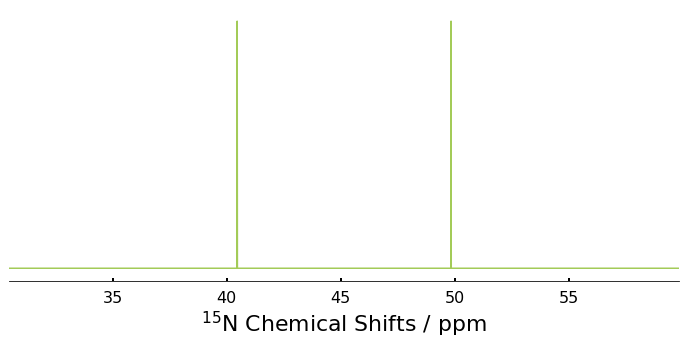

In [70]:
create_plot(7,shielding[numbers==7])

In [623]:
f = np.arange((min(shielding)-increment[sp]), (max(shielding)+increment[sp]), 0.01)
i = np.zeros(len(f))
shielding=np.round(shielding,decimals=2)
for it,x in enumerate(f):
    if x in shielding:
        print x
        i[it]==1

In [626]:
idx=np.isin(f,shielding.tolist())

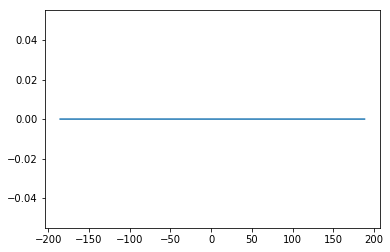

In [630]:
plt.plot(f,i)

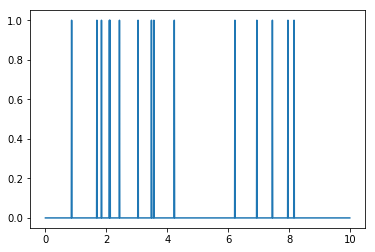

In [351]:
plt.plot(t,i)

(array([ 2.,  0.,  0., ...,  0.,  0.,  2.]),
 array([-124.02      , -123.94160667, -123.86321333, ...,  111.00321333,
         111.08160667,  111.16      ]),
 <a list of 3000 Patch objects>)

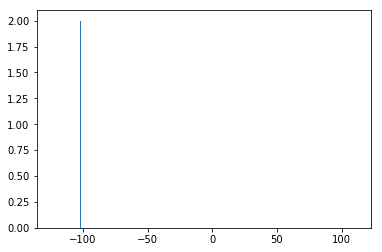

In [323]:
plt.hist(shielding[numbers == sp],bins=3000)

In [ ]:
sps = list(set(frame.get_atomic_numbers()).intersection([1, 6, 7, 8]))
print sps
for ii,sp in enumerate(sps):
    intensities=np.ones(len(shielding[numbers == sp]))
    print shielding[numbers == sp]
    plt.hist(shielding[numbers == sp],bins=300)
    

In [68]:
import json

shielding = np.zeros((len(frame),))
sps = list(set(frame.get_atomic_numbers()).intersection([1, 6, 7, 8]))
train_sizes = {1:30000,6:19532,7:12760,8:14770}

numbers = frame.get_atomic_numbers()

for ii,sp in enumerate(sps):
    kernel_test = np.zeros((train_sizes[sp],len(numbers[numbers==sp])))
    kk = np.zeros((train_sizes[sp],len(numbers[numbers==sp])))
    model_msk = load_model_data_msk(sp, 'msk')
    msk_coefs = model_msk['msk_params']
    print msk_coefs
    for cutoff in [2,3,4,5,6,7]:
        atoms = ase2qp(frame)
        model = load_model_data_msk(sp,cutoff)
        ll = list(sps)
        ll.remove(sp)
        soap_params = dict(
            centerweight=1., cutoff_transition_width=0.5, spkitMax=spkitMax,
            nocenters=ll, is_fast_average=False, chem_channels=False, dispbar=True
        )
        soap_params.update(model['soap_params'])

        descriptor = get_fingerprints([atoms], soap_params, nprocess=1, sp=sp)

        np.dot(model['soap_ref'], descriptor.T,out=kk)
        np.add(np.multiply(msk_coefs[cutoff],kk,out=kk),kernel_test,out=kernel_test)


    y_pred = predict(kernel_test, model_msk['model'].alpha, model_msk['model'].csi)
    if slopes!=None:
        slope=slopes[sp]
        intercept=intercepts[sp]
        y_pred=shielding2shifts(y_pred,slope,intercept)

    shielding[numbers == sp] = y_pred

np.round(shielding, decimals=2, out=shielding)

../data/model_sp_O_c_msk.pck
{2: 256, 3: 128, 4: 32, 5: 8, 6: 8, 7: 1}
../data/model_sp_O_c_2.pck
../data/model_sp_O_c_3.pck
../data/model_sp_O_c_4.pck
../data/model_sp_O_c_5.pck
../data/model_sp_O_c_6.pck
../data/model_sp_O_c_7.pck
../data/model_sp_H_c_msk.pck
{2: 256, 3: 128, 4: 32, 5: 8, 6: 8, 7: 1}
../data/model_sp_H_c_2.pck
../data/model_sp_H_c_3.pck
../data/model_sp_H_c_4.pck
../data/model_sp_H_c_5.pck
../data/model_sp_H_c_6.pck
../data/model_sp_H_c_7.pck
../data/model_sp_C_c_msk.pck
{2: 256, 3: 128, 4: 64, 5: 16, 6: 8, 7: 1}
../data/model_sp_C_c_2.pck
../data/model_sp_C_c_3.pck
../data/model_sp_C_c_4.pck
../data/model_sp_C_c_5.pck
../data/model_sp_C_c_6.pck
../data/model_sp_C_c_7.pck
../data/model_sp_N_c_msk.pck
{2: 256, 3: 128, 4: 32, 5: 8, 6: 8, 7: 1}
../data/model_sp_N_c_2.pck
../data/model_sp_N_c_3.pck
../data/model_sp_N_c_4.pck
../data/model_sp_N_c_5.pck
../data/model_sp_N_c_6.pck
../data/model_sp_N_c_7.pck


array([ -5.48700000e+01,  -5.48700000e+01,   1.47160000e+02,
         1.47160000e+02,  -2.25250000e+02,  -2.25250000e+02,
         4.04600000e+01,   4.04600000e+01,   4.98400000e+01,
         4.98400000e+01,   1.39850000e+02,   1.39850000e+02,
         8.53200000e+01,   8.53200000e+01,   1.56580000e+02,
         1.56580000e+02,   1.49420000e+02,   1.49420000e+02,
         1.09660000e+02,   1.09660000e+02,   9.11700000e+01,
         9.11700000e+01,   1.48020000e+02,   1.48020000e+02,
         8.43100000e+01,   8.43100000e+01,   1.22600000e+02,
         1.22600000e+02,   1.10830000e+02,   1.10830000e+02,
         1.69670000e+02,   1.69670000e+02,   1.76830000e+02,
         1.76830000e+02,   1.20850000e+02,   1.20850000e+02,
         1.02100000e+01,   1.02100000e+01,   4.58700000e+01,
         4.58700000e+01,  -3.41000000e+00,  -3.41000000e+00,
         1.57000000e+00,   1.57000000e+00,  -3.92000000e+00,
        -3.92000000e+00,   5.70000000e-01,   5.70000000e-01,
        -3.54000000e+00,

In [46]:
shielding[numbers == 6]

array([ 139.85,  139.85,   85.32,   85.32,  156.58,  156.58,  149.42,
        149.42,  109.66,  109.66,   91.17,   91.17,  148.02,  148.02,
         84.31,   84.31,  122.6 ,  122.6 ,  110.83,  110.83,  169.67,
        169.67,  176.83,  176.83,  120.85,  120.85,   10.21,   10.21,
         45.87,   45.87])

In [31]:
def shielding2shifts(shielding,slope,intercept):
    shifts=intercept-slope*shielding
    return shifts

[8, 1, 6, 7]


In [51]:
from ase.io import read
import numpy as np
frame=read('file_examples/EDEBUK.xyz')
shielding = np.zeros((len(frame),))
print shielding
sps = list(set(frame.get_atomic_numbers()).intersection([1, 6, 7, 8]))

for ii,sp in enumerate(sps):
    atoms = ase2qp(frame)
    model = load_model_data(sp)
    ll = list(sps)
    ll.remove(sp)
    soap_params = dict(
        centerweight=1., cutoff_transition_width=0.5, spkitMax=spkitMax,
        nocenters=ll, is_fast_average=False, chem_channels=False, dispbar=True
    )
    soap_params.update(model['soap_params'])

    descriptor = get_fingerprints([atoms], soap_params, nprocess=1, sp=sp)

    kernel_test = np.dot(model['soap_ref'], descriptor.T)
    print sp
    y_pred = predict(kernel_test, model['model'].alpha, model['model'].csi)
    slope=float(slopes[sp])
    intercept=float(intercepts[sp])
    y_pred=shielding2shifts(y_pred,slope,intercept)
    shielding[frame.get_atomic_numbers() == sp] = y_pred
    print shielding

[ 0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.
  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.
  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.
  0.  0.  0.  0.  0.  0.  0.  0.  0.  0.]
8
[ -58.83001516  -58.83001835  156.34526656  156.34525533 -244.2945443
 -244.29454166    0.            0.            0.            0.            0.
    0.            0.            0.            0.            0.            0.
    0.            0.            0.            0.            0.            0.
    0.            0.            0.            0.            0.            0.
    0.            0.            0.            0.            0.            0.
    0.            0.            0.            0.            0.            0.
    0.            0.            0.            0.            0.            0.
    0.            0.            0.            0.            0.            0.
    0.            0.            0.            0.   

In [46]:
slopes={1:1,6:1,7:1,8:1}
intercepts={1:30.8,6:169.5,7:0,8:0}

In [52]:
slopes={1:1,6:1,7:1,8:1}
intercepts={1:30.8,6:169.5,7:0,8:0}

In [60]:
print float(slopes[8]), intercepts[8]

1.0 0


In [61]:
import json

In [65]:
minchia=json.dumps(slopes)

In [63]:
minchia=json.load(slopes)

AttributeError: 'dict' object has no attribute 'read'

In [66]:
from pprint import pprint
pprint(minchia)

'{"8": 1, "1": 1, "6": 1, "7": 1}'


In [69]:
json.load(minchia)

AttributeError: 'str' object has no attribute 'read'

In [71]:
print slopes

{8: 1, 1: 1, 6: 1, 7: 1}


In [72]:
print minchia

{"8": 1, "1": 1, "6": 1, "7": 1}


In [76]:
json.load(minchia[1])

AttributeError: 'str' object has no attribute 'read'

In [77]:
from flask import request,jsonify,url_for,redirect


In [107]:
a='1000'
print float(a)

1000.0


In [126]:
from ase.io import read,write
frame=read('/Users/fedeparuzzo/ML-NMR/QEspresso/Cocaine/QEOutput/frm_0001.scf.out',format='espresso-out')

In [127]:
print frame

Atoms(symbols='C34H42N2O8', pbc=True, cell=[[8.567100126855031, 0.0, 0.0], [0.0, 9.645800838027602, 0.0], [-3.0694034992493666, 0.0, 9.851094258367429]], calculator=SinglePointCalculator(...))


In [128]:
def is_proper_crystal(frame):


    try:

        sps = frame.get_atomic_numbers()
        Natoms = frame.get_number_of_atoms()
        if Natoms == 0 or len(sps) == 0:
            raise WrongAtomFormat
    except:

        raise WrongAtomFormat

    try:

        cell = frame.get_cell()
        if np.allclose(cell, np.zeros((3, 3))) is True:
            raise WrongCellFormat
    except:

        raise WrongCellFormat

    try:
        vol = frame.get_volume()
        if float(Natoms) / vol > 0.234 or vol / float(Natoms) < 0.01:
            raise WrongDensity
    except:
        raise WrongDensity

In [144]:
import random
shielding=[]
for i in range(86):
    shielding.append(random.random())
    
shielding=np.array(shielding)

In [178]:
 shield_out

array(['<b>{0.99}</b>', '<b>{0.71}</b>', '<b>{0.44}</b>', '<b>{0.04}</b>',
       '<b>{0.66}</b>', '<b>{0.93}</b>', '<b>{0.10}</b>', '<b>{0.55}</b>',
       '<b>{0.12}</b>', '<b>{0.75}</b>', '<b>{0.20}</b>', '<b>{0.01}</b>',
       '<b>{0.54}</b>', '<b>{0.80}</b>', '<b>{0.41}</b>', '<b>{0.75}</b>',
       '<b>{0.12}</b>', '<b>{0.09}</b>', '<b>{0.96}</b>', '<b>{0.74}</b>',
       '<b>{0.29}</b>', '<b>{0.03}</b>', '<b>{0.35}</b>', '<b>{0.64}</b>',
       '<b>{0.84}</b>', '<b>{0.90}</b>', '<b>{0.85}</b>', '<b>{0.20}</b>',
       '<b>{0.31}</b>', '<b>{0.51}</b>', '<b>{0.88}</b>', '<b>{0.87}</b>',
       '<b>{0.50}</b>', '<b>{0.77}</b>', '<b>{0.78}</b>', '<b>{0.60}</b>',
       '<b>{0.92}</b>', '<b>{0.47}</b>', '<b>{0.56}</b>', '<b>{0.50}</b>',
       '<b>{0.57}</b>', '<b>{0.44}</b>', '<b>{0.07}</b>', '<b>{0.71}</b>',
       '<b>{0.58}</b>', '<b>{0.80}</b>', '<b>{0.74}</b>', '<b>{0.81}</b>',
       '<b>{0.50}</b>', '<b>{0.16}</b>', '<b>{0.78}</b>', '<b>{0.54}</b>',
       '<b>{0.84}</b>', '

In [205]:
from ase.io.extxyz import write_xyz
numbers = frame.get_atomic_numbers()
positions = frame.get_positions()
cell = frame.get_cell()
pbc = frame.get_pbc()
new_frame = Atoms(numbers=numbers, positions=positions, cell=cell, pbc=pbc)
shielding=np.around(shielding, decimals=2)
shield_out=[]
for i in range(len(shielding)):
    shield_out.append('!{}?'.format(shielding[i]))
shield_out=np.array(shield_out)
new_frame.set_array('ChemicalShielding'.encode('ascii', 'ignore'), shielding)
# prop_ref = frame[0].get_array('CS')[np.where(numbers == 1)[0]]

# print new_frame.get_array('ChemicalShielding')
# write(fn,new_frame,format='extxyz')
f_obj = DummyFileObject()

write_xyz(f_obj, new_frame)

In [201]:
shield_out

array(['!0.99?', '!0.71?', '!0.44?', '!0.04?', '!0.66?', '!0.93?', '!0.1?',
       '!0.55?', '!0.12?', '!0.75?', '!0.2?', '!0.01?', '!0.54?', '!0.8?',
       '!0.41?', '!0.75?', '!0.12?', '!0.09?', '!0.96?', '!0.74?',
       '!0.29?', '!0.03?', '!0.35?', '!0.64?', '!0.84?', '!0.9?', '!0.85?',
       '!0.2?', '!0.31?', '!0.51?', '!0.88?', '!0.87?', '!0.5?', '!0.77?',
       '!0.78?', '!0.6?', '!0.92?', '!0.47?', '!0.56?', '!0.5?', '!0.57?',
       '!0.44?', '!0.07?', '!0.71?', '!0.58?', '!0.8?', '!0.74?', '!0.81?',
       '!0.5?', '!0.16?', '!0.78?', '!0.54?', '!0.84?', '!0.52?', '!0.3?',
       '!0.33?', '!0.96?', '!0.11?', '!0.44?', '!0.59?', '!0.45?',
       '!0.64?', '!0.28?', '!0.55?', '!0.93?', '!0.71?', '!0.29?',
       '!0.97?', '!0.91?', '!0.15?', '!0.38?', '!0.91?', '!0.74?', '!0.7?',
       '!0.45?', '!0.06?', '!0.97?', '!0.17?', '!0.66?', '!0.56?',
       '!0.74?', '!0.97?', '!0.8?', '!0.38?', '!0.45?', '!0.36?'],
      dtype='|S6')

In [265]:
print f_obj.read()


86
Lattice="8.56710012686 0.0 0.0 0.0 9.64580083803 0.0 -3.06940349925 0.0 9.85109425837" Properties=species:S:1:pos:R:3:Z:I:1:ChemicalShielding:R:1 pbc="T T T"
C      -0.46361890       0.05158337       9.41449342        6       0.99000000 
C       5.96131382       4.87448293       0.43659827        6       0.71000000 
C       3.84547825       9.29780951       0.40313689        6       0.44000000 
C       1.65221666       4.47490910       9.44795480        6       0.04000000 
C       3.54175056       9.61461231       1.87095358        6       0.66000000 
C       1.95594435       4.79171189       7.98013811        6       0.93000000 
C       2.99704577       1.38297327       2.05857650        6       0.10000000 
C       2.50064914       6.20587369       7.79251519        6       0.55000000 
C       1.88557590       1.65043813       1.03003444        6       0.12000000 
C       3.61211901       6.47333855       8.82105725        6       0.75000000 
C       0.77135342       0.56923754    

In [283]:
for line in f_obj.read().readlines():
    print line

AttributeError: 'str' object has no attribute 'readlines'

In [284]:
xyz = str(f_obj.read()).replace(
        '\n', '<br>').replace(' ', '&nbsp;')

In [285]:
tmp=xyz.split('<br>')

In [286]:
tmp

['86',
 'Lattice="8.56710012686&nbsp;0.0&nbsp;0.0&nbsp;0.0&nbsp;9.64580083803&nbsp;0.0&nbsp;-3.06940349925&nbsp;0.0&nbsp;9.85109425837"&nbsp;Properties=species:S:1:pos:R:3:Z:I:1:ChemicalShielding:R:1&nbsp;pbc="T&nbsp;T&nbsp;T"',
 'C&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;-0.46361890&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;0.05158337&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;9.41449342&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;6&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;0.99000000&nbsp;',
 'C&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;5.96131382&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;4.87448293&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;0.43659827&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;6&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;0.71000000&nbsp;',
 'C&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;3.84547825&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;9.29780951&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;0.40313689&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;6&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;

In [287]:
tmp=xyz.split('<br>')
for it in range(2,len(tmp)):
    tmp[it]=rreplace(tmp[it],'&nbsp;','&nbsp;<b>',9)
    tmp[it]=rreplace(tmp[it],'&nbsp;<b>','</b>&nbsp;',8)
    tmp[it]=rreplace(tmp[it],'</b>&nbsp;','&nbsp;',7)
    tmp[it]=rreplace(tmp[it],'000000','',1)
xyz='<br>'.join([str(x) for x in tmp])

In [288]:
xyz

'86<br>Lattice="8.56710012686&nbsp;0.0&nbsp;0.0&nbsp;0.0&nbsp;9.64580083803&nbsp;0.0&nbsp;-3.06940349925&nbsp;0.0&nbsp;9.85109425837"&nbsp;Properties=species:S:1:pos:R:3:Z:I:1:ChemicalShielding:R:1&nbsp;pbc="T&nbsp;T&nbsp;T"<br>C&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;-0.46361890&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;0.05158337&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;9.41449342&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;<b>6</b>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;0.99&nbsp;<br>C&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;5.96131382&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;4.87448293&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;0.43659827&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;<b>6</b>&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;0.71&nbsp;<br>C&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;3.84547825&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;9.29780951&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;0.40313689&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;&nbsp;<b>6</b>&nbsp;&nbsp;&nbsp;&nbsp;&n

In [209]:
def rreplace(s, old, new, occurrence):
    li = s.rsplit(old, occurrence)
    return new.join(li)


In [206]:
print f_obj.read()

86
Lattice="8.56710012686 0.0 0.0 0.0 9.64580083803 0.0 -3.06940349925 0.0 9.85109425837" Properties=species:S:1:pos:R:3:Z:I:1:ChemicalShielding:R:1 pbc="T T T"
C      -0.46361890       0.05158337       9.41449342        6       0.99000000 
C       5.96131382       4.87448293       0.43659827        6       0.71000000 
C       3.84547825       9.29780951       0.40313689        6       0.44000000 
C       1.65221666       4.47490910       9.44795480        6       0.04000000 
C       3.54175056       9.61461231       1.87095358        6       0.66000000 
C       1.95594435       4.79171189       7.98013811        6       0.93000000 
C       2.99704577       1.38297327       2.05857650        6       0.10000000 
C       2.50064914       6.20587369       7.79251519        6       0.55000000 
C       1.88557590       1.65043813       1.03003444        6       0.12000000 
C       3.61211901       6.47333855       8.82105725        6       0.75000000 
C       0.77135342       0.56923754    

In [146]:
class DummyFileObject(object):
    def __init__(self):
        self.data = ''
    def write(self,text):
        self.data += text
    def read(self):
        return self.data